# Número reproductivo efectivo $R_t$ de varicela: cálculo nacional por inicio de síntomas

Este cuaderno estima un $R_t$ nacional diario para 2008–2025 a partir de **registros individuales de Sivigila agrupados por `INI_SIN`**, la fecha de inicio de síntomas. Reproduce el modelo, la previa, los pesos seriales, las ventanas de 14 días y las comprobaciones del [cuaderno por fecha de notificación](05_rt_nacional_diario.ipynb), pero cambia **la fecha que determina el día de cada caso**. La salida es [`rt_national_symptom_daily.csv`](../docs/data_processed/numero_reproductivo/rt_national_symptom_daily.csv). No se reconstruyen días a partir de totales semanales.

$R_t$ es el número reproductivo instantáneo: infecciones secundarias esperadas por persona infectada si las condiciones del día $t$ persistieran durante su período infeccioso. Al aplicarlo a **casos por inicio de síntomas**, el índice temporal se aproxima mejor al intervalo serial bibliográfico que con la fecha de notificación, pero sigue sin observar infecciones ni pares transmisor–secundario. La fecha de síntomas puede faltar, registrarse con error o conocerse solo después del día al que se atribuye. La grave falta de `INI_SIN` en 2013 se conserva y audita explícitamente.

## 1. Procedencia, filtros y lectura de `INI_SIN`

Los [CSV individuales de 2007–2025](../data/sivigila/csv/) son copias locales de los archivos del evento 831 (varicela). Su [README](../data/sivigila/README.md) y [diccionario](../data/sivigila/dic_datos.md) describen los campos; la [tabla DIVIPOLA](../data/sivigila/DIVIPOLA-_Códigos_municipios_20261007.csv) define los municipios válidos de residencia. El [script de procesamiento original](https://github.com/thesis-varicella-colombia/data-processing/blob/main/scripts/processing/calculate_date_weekly_sivigila.py) documenta el tratamiento especial de 2013. Sivigila entrega filas individuales; el [Parquet por semana de inicio de síntomas](../data/sivigila_integrado_symptom_semanal_municipal.parquet/) fue agregado en `data-processing`.

Reproducimos sus filtros: `ANO` coincide con el año del archivo; `COD_EVE=831`; municipio de residencia presente en DIVIPOLA tras homologar `27086→27493`, `94663→94343` y `88000→88001`; `AJUSTE` distinto de 6 y D. Cada fila incluida con fecha interpretable cuenta **una vez**; no se deduplican personas. Los CSV guardan la fecha al inicio de un texto horario. Normalmente `INI_SIN` se interpreta como **día/mes/año**, pero el archivo de **2013 la guarda como mes/día/año**, según la regla del procesamiento de origen. Ignorar esa excepción puede cambiar el día y la semana de un caso o perder fechas. `FEC_NOT`, `ANO` y `SEMANA` no asignan el día en este análisis.

Se leen también archivos de 2007 para cubrir el inicio del año epidemiológico 2008. La semana epidemiológica empieza el domingo y la semana 1 contiene el 4 de enero. El período principal excluye 2007 por la discrepancia de cobertura documentada en el [README de datos](../data/README.md). `quality` audita, por **año del archivo**, cuántas filas pasan los filtros y cuántas tienen `INI_SIN` válida; ese año fuente no siempre coincide con el año epidemiológico de la fecha de síntomas.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import gamma

# Resolve project paths whether this notebook runs from the root or notebooks/.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
from rt_symptom_sivigila import (
    onset_counts, symptom_weekly_reference, build_onset_daily_series, estimate_onset_rt,
)
from epiestim_parametric_weekly import discr_si

# Count individual onset dates, then reconcile them against the onset-week Parquet.
observed, quality = onset_counts()
reference = symptom_weekly_reference()
# Reconcile every valid source record, including dates outside 2008–2025.
assert int(observed.sum()) == reference.attrs["all_year_cases"]
daily, weekly = build_onset_daily_series(observed, reference)
print(f"Registros elegibles con inicio interpretable: {quality.valid_onset.sum():,}")
print(f"Casos por inicio de síntomas en 2008–2025: {daily.cases.sum():,.0f}")
display(quality)
display(daily.head())

Registros elegibles con inicio interpretable: 1,195,823
Casos por inicio de síntomas en 2008–2025: 1,169,098


,source_year,source_rows,included_rows,missing_or_invalid_onset,valid_onset,valid_onset_percent
0,2007,26484,26441,0,26441,100.000000
1,2008,63714,63491,0,63491,100.000000
2,2009,73135,72950,0,72950,100.000000
3,2010,74033,73715,0,73715,100.000000
4,2011,121295,120772,0,120772,100.000000
5,2012,100438,100195,15,100180,99.985029
6,2013,93835,93606,55686,37920,40.510224
7,2014,108246,107924,0,107924,100.000000
8,2015,111033,110714,0,110714,100.000000
9,2016,112400,111984,0,111984,100.000000


,date,year,week,cases,missing_week
0,2007-12-30,2008,1,57.0,False
1,2007-12-31,2008,1,113.0,False
2,2008-01-01,2008,1,170.0,False
3,2008-01-02,2008,1,105.0,False
4,2008-01-03,2008,1,81.0,False


## 2. Reconciliación semanal, faltantes y cobertura

La serie cubre cada día de las 940 semanas epidemiológicas de 2008–2025. Dentro de una semana con total en el [Parquet `symptom`](../data/sivigila_integrado_symptom_semanal_municipal.parquet/), un día sin filas válidas recibe **cero casos observados**. Si no existe total semanal, sus siete días quedan **sin dato (`NaN`)**. `build_onset_daily_series` exige que la suma de cada semana observada coincida **exactamente** con el Parquet local y detiene la ejecución ante cualquier diferencia. Esta reconciliación verifica consistencia entre dos agregaciones de los mismos registros; no valida que los casos faltantes hayan sido captados por la vigilancia.

Hay **20 semanas sin total**: 2008-S52 y S53, y **18 semanas de 2013**. Las interrupciones de 2013 coinciden con la escasa completitud de `INI_SIN` en el archivo fuente de ese año: **37.920 de 93.606** registros elegibles (40,5 %) tienen fecha interpretable; faltan **55.686**. Otros 15 registros con fecha ausente o inválida corresponden al archivo de 2012. Estas ausencias no se imputan como cero. La función de infectividad se reinicia en cada tramo continuo de días observados; dentro de un tramo sigue sin recuperar casos cuyo inicio no fue consignado. Por eso, una curva posterior de 2013 o de las primeras semanas de 2014 puede estar fuertemente distorsionada aun cuando su intervalo creíble condicional sea estrecho.

Como comprobación adicional, el total de **1.195.823** registros individuales con `INI_SIN` interpretable entre todos los archivos de origen coincide con el total de casos del Parquet `symptom` en **todos sus años**, incluidos los bordes fuera de 2008–2025. La serie principal selecciona **1.169.098** casos asignados a años epidemiológicos 2008–2025.

In [2]:
# Display every absent week; do not replace its seven days with zero.
missing_weeks = weekly.loc[weekly.missing_week, ["year", "week", "week_start"]]
assert len(missing_weeks) == 20
assert missing_weeks.year.value_counts().to_dict() == {2013: 18, 2008: 2}
assert daily.loc[daily.missing_week, "cases"].isna().all()
assert int(daily.missing_week.sum()) == 7 * len(missing_weeks)

def preserve_missing(values):
    """Keep a weekly total undefined when all seven daily values are missing."""
    return values.sum(min_count=1)

weekly_check = daily.groupby(["year", "week"], as_index=False).agg(
    cases=("cases", preserve_missing)
)
assert np.allclose(weekly_check.cases.fillna(-1), weekly.cases.fillna(-1))
print("Weeks without a symptom-onset total:")
display(missing_weeks)
print("Coverage by source year near the 2013 anomaly:")
display(quality.loc[quality.source_year.between(2012, 2014),
                    ["source_year", "included_rows", "valid_onset",
                     "missing_or_invalid_onset", "valid_onset_percent"]].round(2))

Weeks without a symptom-onset total:


,year,week,week_start
51,2008,52,2008-12-21
52,2008,53,2008-12-28
263,2013,3,2013-01-13
264,2013,4,2013-01-20
268,2013,8,2013-02-17
272,2013,12,2013-03-17
273,2013,13,2013-03-24
276,2013,16,2013-04-14
277,2013,17,2013-04-21
281,2013,21,2013-05-19


Coverage by source year near the 2013 anomaly:


,source_year,included_rows,valid_onset,missing_or_invalid_onset,valid_onset_percent
5,2012,100195,100180,15,99.99
6,2013,93606,37920,55686,40.51
7,2014,107924,107924,0,100.00


## 3. Intervalo de generación, intervalo serial y pesos diarios

Para un par transmisor $i$–caso secundario $j$, sean $T$ la fecha de **infección**, $O$ la de **inicio de síntomas** y $L=O-T$ el período de incubación. El **intervalo de generación** $G_{ij}=T_j-T_i$ separa las infecciones; el **intervalo serial** $S_{ij}=O_j-O_i$ separa los inicios de síntomas. Se cumple

$$S_{ij}=G_{ij}+L_j-L_i.$$

Si los períodos de incubación de transmisores y secundarios tienen la misma media, las medias de $G$ y $S$ pueden coincidir sin que coincidan sus distribuciones ([Lehtinen et al., 2021](https://pmc.ncbi.nlm.nih.gov/articles/PMC7879757/)). En esta ruta $I_d$ **sí cuenta inicios de síntomas observados** en el día $d$, por lo que los pesos seriales están definidos en la misma escala temporal que los conteos. Aun así, $I_d$ no cuenta todas las infecciones: omite casos sin fecha válida y desplaza los eventos respecto de la fecha de contagio. [Cori et al. (2013)](https://pmc.ncbi.nlm.nih.gov/articles/PMC3816335/) discuten los supuestos que permiten usar intervalos seriales en lugar de intervalos de generación; [Gostic et al. (2020)](https://doi.org/10.1371/journal.pcbi.1008409) explican el rezago entre infección y observación. La comparación con la [ruta por notificación](05_rt_nacional_diario.ipynb) examina el cambio de calendario, no demuestra cuál reconstruye mejor las infecciones.

El [análisis individual de demoras](03_demora_notificacion_sivigila.ipynb) encontró, entre registros con ambas fechas interpretables de 2008–2025 ($n=1.169.382$), mediana de **2 días** y rango intercuartílico **1–4 días** entre `INI_SIN` y `FEC_NOT`; **67,4 %** se notificaron entre cero y tres días después del inicio. La proporción con demora mayor que siete días fue **4,6 % en 2009–2011** y **17,7 % en 2019–2025**. Las fechas de síntomas eliminan ese desplazamiento *dentro de los registros con fecha*, pero llegan retrospectivamente y no corrigen la selección de fechas faltantes. En particular, el archivo de 2013 tiene menos de la mitad de `INI_SIN` interpretables. Ni ese análisis de demoras ni los CSV identifican pares de transmisión con los que estimar la distribución serial ([Charniga et al., 2024](https://pmc.ncbi.nlm.nih.gov/articles/PMC11516000/)).

Usamos la estimación de [Vink et al. (2014), tabla 3](https://doi.org/10.1093/aje/kwu209) basada en **184 intervalos** de varicela recogidos por [R. E. H. Simpson (1952)](https://doi.org/10.1016/S0140-6736(52)91357-3) en Inglaterra. Su modelo normal para $S$ tiene **media 14,1 días** (tiempo promedio entre síntomas de pares vinculados) y **desviación estándar 2,4 días** (dispersión entre intervalos, no error estándar de la media). Vink et al. obtuvieron media agrupada de 14,0 días entre tres estudios. Son parámetros bibliográficos, no colombianos.

Para seguir `parametric_si` de EpiEstim aproximamos esos momentos con una **Gamma desplazada un día**: $S=1+X$, $X\sim\operatorname{Gamma}(\alpha,\theta)$, forma $\alpha=((\mu-1)/\sigma)^2$ y **escala** $\theta=\sigma^2/(\mu-1)$. La función [`discr_si()`](https://mrc-ide.github.io/EpiEstim/reference/discr_si.html) convierte esa distribución continua en pesos diarios $w_s$ no negativos que suman 1. La [comparación R–Python](04_comparacion_epiestim_r_python.ipynb) verificó numéricamente esta función en los tramos ensayados; el cálculo completo por síntomas conserva además la regla de historia suficiente descrita a continuación.

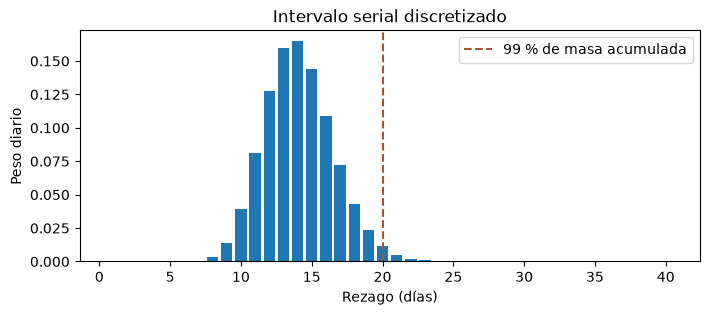

Suma de pesos hasta 89 días: 1.00000000; peso en el día 14: 0.165; rezago 99 %: 20 días


In [3]:
# Convert the continuous serial interval into one weight per daily lag.
weights = discr_si(np.arange(90), 14.1, 2.4)
# The first lag reaching 99% cumulative mass sets the minimum history.
lag_99 = int(np.searchsorted(np.cumsum(weights), .99))
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(np.arange(1, 41), weights[1:41], width=.8)
ax.axvline(lag_99, color="#a45632", ls="--", label="99 % de masa acumulada")
ax.set(xlabel="Rezago (días)", ylabel="Peso diario", title="Intervalo serial discretizado")
ax.legend()
plt.show()
print(f"Suma de pesos hasta 89 días: {weights.sum():.8f}; peso en el día 14: {weights[14]:.3f}; rezago 99 %: {lag_99} días")

## 4. Renovación sobre casos con inicio de síntomas e historia suficiente

En la formulación ideal de [Fraser (2007)](https://doi.org/10.1371/journal.pone.0000758) y [Cori et al. (2013)](https://doi.org/10.1093/aje/kwt133), $C_d$ son **infecciones nuevas** no observadas y $R_d$ es el número reproductivo instantáneo del día $d$. Con pesos $w_s$ para cada rezago,

$$\Lambda_d^{\mathrm{inf}}=\sum_{s\geq1}w_s C_{d-s},\qquad
\mathbb E[C_d\mid C_{<d},R_d]=R_d\Lambda_d^{\mathrm{inf}}.$$

$\Lambda_d^{\mathrm{inf}}$ es una **suma calculada de casos anteriores ponderados por antigüedad**, no el número observado de personas infecciosas. Diez casos con peso 0,2 aportan dos unidades. La igualdad fija solo la media condicional; [Cori et al. (2013)](https://doi.org/10.1093/aje/kwt133) añaden una verosimilitud Poisson, que también iguala varianza y media condicionales.

Sustituimos aquí las infecciones $C_d$ por $I_d$, **registros cuyo `INI_SIN` es el día $d$**, y calculamos $\Lambda_d=\sum_{s\geq1}w_sI_{d-s}$. Aproximamos $I_d\mid I_{<d},R_d\sim\operatorname{Poisson}(R_d\Lambda_d)$. Esta formulación con inicios de síntomas y pesos seriales es más coherente temporalmente que aplicar esos pesos a notificaciones, pero sigue siendo un modelo de registros observados. No identifica quién contagió a quién ni corrige fechas faltantes, errores retrospectivos o sobredispersión.

Cuando falta una semana entera, la secuencia se divide en tramos continuos: no se asignan ceros a los días desconocidos y no se usa la historia anterior al hueco para calcular $\Lambda_d$ posterior. Además, exigimos que **cada día de los 14 de una ventana** tenga disponibles al menos el **99 % de la masa** de los pesos seriales. Con los parámetros principales eso requiere **20 días previos** dentro del mismo tramo antes del primer día de la ventana. La primera estimación termina el **1 de febrero de 2008**; tras las semanas 2008-S52–S53, el **6 de febrero de 2009**. En 2013 las interrupciones impiden muchas estimaciones. Esta regla controla la historia truncada, pero no recupera los casos con `INI_SIN` ausente dentro de semanas observadas.

## 5. Previa y posterior Gamma en una ventana de 14 días

Para cada día final $t$ definimos **un solo parámetro $R_t$**, supuesto constante durante los días $t-13,\ldots,t$. El modelo asigna a cada conteo diario de esa ventana media $R_t\Lambda_d$ y varianza condicional igual a esa media. La constancia local suaviza cambios rápidos: se publica una estimación **cada día**, pero cada una reúne 14 días de datos. Elegimos esa duración porque se acerca a la media serial bibliográfica de 14,1 días y cubre dos ciclos semanales de registro por inicio de síntomas; la [guía general de EpiEstim](https://mrc-ide.github.io/EpiEstim/articles/full_EpiEstim_vignette.html) sugiere empezar con ventanas al menos tan largas como la media serial. [Vink et al. (2014)](https://doi.org/10.1093/aje/kwu209) no proponen una ventana óptima para $R_t$. En esta ruta de casos **diarios observados** no rige la restricción adicional de longitud mínima por agregación semanal de la [guía para datos agregados](https://mrc-ide.github.io/EpiEstim/articles/EpiEstim_aggregated_data.html).

La **previa** de cada $R_t$, antes de utilizar los conteos de su ventana, es $\operatorname{Gamma}(a=1,b=0{,}2)$, con **forma** $a$ y **tasa** $b$; no debe confundirse con la Gamma *de escala* usada para el intervalo serial. En una Gamma de tasa, $\mathbb E[R_t]=a/b$ y $\operatorname{DE}(R_t)=\sqrt a/b$. Elegir media y desviación estándar ambas iguales a 5 da $a=(5/5)^2=1$ y $b=5/5^2=0{,}2$, varianza 25 e intervalo previo central del 95 % aproximadamente $[0{,}13;18{,}44]$. La media 5 es una expectativa **previa** y la desviación 5 expresa dispersión amplia; no son estimaciones de varicela colombiana. El [suplemento de Cori et al. (2013), apéndice 10](https://bosailiteracy.org/wp-content/uploads/2020/05/Supplementary-Data.pdf) comparó previas de medias 1, 5, 10 y 50 con desviaciones iguales a sus medias; [Thompson et al. (2019)](https://doi.org/10.1016/j.epidem.2019.100356) emplearon 5 y 5 siguiendo a Cori, y [EpiEstim](https://mrc-ide.github.io/EpiEstim/reference/estimate_R.html) los usa por defecto.

La amplitud previa es coherente con no imponer el mismo rango estrecho a todas las ventanas nacionales. [Barrero Guevara et al. (2023)](https://doi.org/10.1093/infdis/jiad244) documentan heterogeneidad espacial y estacional de la varicela colombiana; el [panel C de su Figura 4](https://pmc.ncbi.nlm.nih.gov/articles/PMC10503957/figure/jiad244-F4/) muestra componentes estacionales de la **tasa de contagio en otro modelo** para Cúcuta y Bogotá. Esas curvas no son valores de nuestro $R_t$ ni calibran $a$ o $b$. [Pawaskar et al. (2022)](https://doi.org/10.1016/j.vaccine.2022.07.012) documentan menor incidencia tras la vacunación, pero tampoco estiman esta previa. La elección sigue siendo metodológica y se contrasta abajo con una alternativa.

La conjugación Poisson–Gamma da la **posterior**, distribución después de incorporar los 14 conteos:

$$R_t\mid I\sim\operatorname{Gamma}\left(a+\sum_{d=t-13}^{t}I_d,\quad b+\sum_{d=t-13}^{t}\Lambda_d\right).$$

Así, $a=1$ se suma como un **pseudocaso** y $b=0{,}2$ como 0,2 unidades de infectividad acumulada. Publicamos la media posterior y sus cuantiles 2,5 % y 97,5 %. El intervalo entre esos cuantiles contiene el 95 % de probabilidad **condicional al modelo y a los supuestos fijados**; no abarca fechas de síntomas faltantes o erróneas, incertidumbre serial, mezcla territorial ni desviaciones de la varianza Poisson. Una banda estrecha no demuestra que $R_t$ biológico sea conocido con esa precisión.

**Alcance temporal.** La posterior se indexa por el día de síntomas, no por el de infección ni por el momento en que el registro estuvo disponible. Por eso la estimación por `INI_SIN` es **retrospectiva**: no equivale a una estimación que pudiera haberse producido en tiempo real ese mismo día. La baja completitud de 2013 tampoco queda incorporada en los intervalos creíbles.

In [4]:
# Fit the shared daily renewal estimator to symptom-onset counts.
result = estimate_onset_rt(daily, mean_si=14.1, sd_si=2.4, window_days=14,
                           prior_mean=5, prior_sd=5)
# Verify one 14-day posterior directly at the end of 2008-S08.
example = result.loc[(result.year == 2008) & (result.week == 8) & result.rt.notna()].iloc[-1]
end = result.index[result.date.eq(example.date)][0]
window = result.iloc[end-13:end+1]
shape = 1 + window.cases.sum()
rate = .2 + window.infectiousness.sum()
assert len(window) == 14 and np.isclose(shape / rate, example.rt)
assert np.isclose(gamma.ppf(.025, a=shape, scale=1/rate), example.rt_lower_95)
assert np.isclose(gamma.ppf(.975, a=shape, scale=1/rate), example.rt_upper_95)
print(f"Ventana {window.date.iloc[0].date()} a {example.date.date()}: "
      f"{window.cases.sum():.0f} casos, infectividad={window.infectiousness.sum():.2f}")
print(f"Posterior Gamma(forma={shape:.0f}, tasa={rate:.2f}); media={example.rt:.3f}")
# Audit the first publishable date on either side of the 2008 gap.
first_before_gap = result.loc[(result.date < "2008-12-21") & result.rt.notna(), "date"].min()
first_after_gap = result.loc[(result.date > "2009-01-03") & result.rt.notna(), "date"].min()
assert first_before_gap == pd.Timestamp("2008-02-01")
assert first_after_gap == pd.Timestamp("2009-02-06")
print("Primeras estimaciones de cada tramo:", first_before_gap.date(), "y", first_after_gap.date())

Ventana 2008-02-10 a 2008-02-23: 1791 casos, infectividad=1602.67
Posterior Gamma(forma=1792, tasa=1602.87); media=1.118
Primeras estimaciones de cada tramo: 2008-02-01 y 2009-02-06


### Peso observado de la previa

La previa alternativa $\operatorname{Gamma}(1,5)$, también expresada como forma y **tasa**, tiene media 0,2 y desviación estándar 0,2. Mantiene fijos los conteos y los pesos para aislar la influencia de la elección previa; es una comparación deliberadamente exigente, no una propuesta calibrada para Colombia. En ventanas nacionales con muchos casos, el pseudocaso y las 0,2 unidades de infectividad de la previa principal deberían pesar poco frente a los totales observados. La tabla calcula esos mínimos y la diferencia entre medias posteriores; **no** implica invariancia matemática general cuando la incidencia es baja.

En 2013, los conteos observados son una fracción seleccionada de los registros: la sensibilidad numérica a la previa no cuantifica el sesgo causado por las fechas de inicio faltantes.

La tabla de este conjunto muestra un mínimo de **dos** casos en una ventana estimable y una diferencia máxima de **0,42357** en la media posterior al cambiar la previa. Es una señal de que, cerca de los tramos escasos o incompletos, la previa puede dejar de ser despreciable; la aparente precisión de una posterior tampoco repara la pérdida de `INI_SIN`.

In [5]:
# Change only the prior, retaining onset counts and serial weights.
alternative = estimate_onset_rt(daily, prior_mean=.2, prior_sd=.2)
valid = result.rt.notna() & alternative.rt.notna()
cases_14 = result.cases.rolling(14, min_periods=14).sum()
lambda_14 = result.infectiousness.rolling(14, min_periods=14).sum()
comparison_prior = (result.loc[valid, "rt"] - alternative.loc[valid, "rt"]).abs()
display(pd.DataFrame([{
    "ventanas_comparables": int(valid.sum()),
    "mínimo_de_casos_en_14_días": int(cases_14[valid].min()),
    "mínimo_de_infectividad_en_14_días": round(lambda_14[valid].min(), 2),
    "diferencia_media_absoluta_mediana": round(comparison_prior.median(), 5),
    "diferencia_media_absoluta_máxima": round(comparison_prior.max(), 5),
}]))

,ventanas_comparables,mínimo_de_casos_en_14_días,mínimo_de_infectividad_en_14_días,diferencia_media_absoluta_mediana,diferencia_media_absoluta_máxima
0,6180,2,187.78,0.00183,0.42357


## 6. Serie nacional por inicio de síntomas y diagnóstico de 2013

La banda representa únicamente los cuantiles posteriores **condicionales**. La línea horizontal marca $R_t=1$; las líneas verticales señalan aproximadamente las semanas 27 de 2015 y 2019; la franja gris va de 2020-S12 a 2021-S52. Son referencias temporales, no evidencia causal. La serie conserva los huecos semanales y el tiempo de espera por historia suficiente después de cada uno.

El año **2013** aparece sombreado por su baja completitud de `INI_SIN`: solo **40,5 %** de registros elegibles del archivo fuente tienen fecha interpretable y faltan 18 semanas completas por año epidemiológico. Las estimaciones grandes alrededor de finales de 2013 e inicios de 2014 pueden responder a discontinuidades de registro. Para no esconder valores extremos, mostramos una vista general centrada en $R_t\leq2$ **y una vista adicional con toda la escala** del tramo 2013–2014, acompañada de una tabla de máximos. La primera vista recorta el eje, no modifica los datos ni el CSV. La distribución por día de la semana es un diagnóstico descriptivo de fechas de síntomas consignadas; no se usa como corrección del modelo.

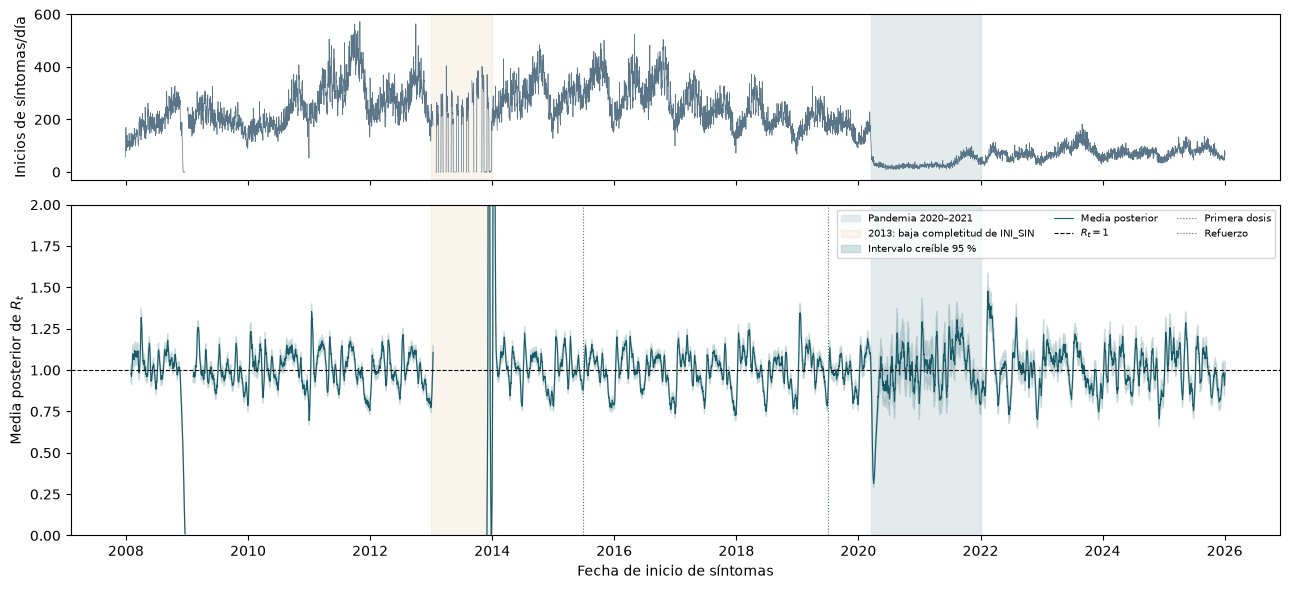

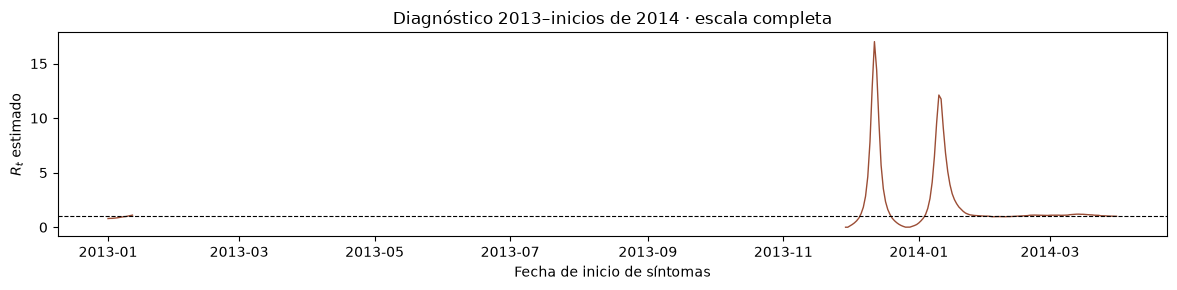

,date,year,week,cases,rt
2174,2013-12-12,2013,50,199.0,17.012117
2175,2013-12-13,2013,50,0.0,14.414552
2173,2013-12-11,2013,50,216.0,12.871926
2203,2014-01-10,2014,2,217.0,12.116426
2204,2014-01-11,2014,2,176.0,11.753686
2176,2013-12-14,2013,50,1.0,9.711402
2202,2014-01-09,2014,2,196.0,9.575265
2205,2014-01-12,2014,3,211.0,9.078797


,count,mean,median
lunes,920,200.2,200.5
martes,920,182.9,193.5
miércoles,920,175.4,180.5
jueves,920,171.6,172.5
viernes,920,176.3,177.0
sábado,920,173.6,176.0
domingo,920,190.6,194.0


Estimaciones diarias: 6,180; semanas sin dato: 20; máximo Rₜ: 17.01


In [6]:
# Plot the entire period and mark the known onset-date quality problem.
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 6), sharex=True,
                               gridspec_kw={"height_ratios": [1, 2]})
pandemic_start = result.loc[(result.year == 2020) & (result.week == 12), "date"].min()
pandemic_end = result.loc[(result.year == 2021) & (result.week == 52), "date"].max() + pd.Timedelta(days=1)
for axis in (ax1, ax2):
    axis.axvspan(pandemic_start, pandemic_end, color="#cbd8dd", alpha=.5,
                label="Pandemia 2020–2021" if axis is ax2 else None)
    axis.axvspan(pd.Timestamp("2013-01-01"), pd.Timestamp("2014-01-01"),
                color="#e9d5b5", alpha=.25,
                label="2013: baja completitud de INI_SIN" if axis is ax2 else None)
ax1.plot(result.date, result.cases, lw=.5, color="#597587")
ax1.set_ylabel("Inicios de síntomas/día")
ax2.fill_between(result.date, result.rt_lower_95, result.rt_upper_95,
                 color="#5a8d92", alpha=.25, label="Intervalo creíble 95 %")
ax2.plot(result.date, result.rt, lw=.8, color="#175a68", label="Media posterior")
ax2.axhline(1, color="black", ls="--", lw=.8, label="$R_t=1$")
for event, label in (("2015-07-01", "Primera dosis"), ("2019-07-01", "Refuerzo")):
    ax2.axvline(pd.Timestamp(event), color="#596b75", ls=":", lw=.8, label=label)
ax2.set(ylabel="Media posterior de $R_t$", xlabel="Fecha de inicio de síntomas", ylim=(0, 2))
ax2.legend(loc="upper right", ncol=3, fontsize=7)
plt.tight_layout()
plt.show()

# Show the 2013–2014 extreme estimates on their full scale rather than hiding them.
problem_period = result.loc[result.date.between("2013-01-01", "2014-03-31")]
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(problem_period.date, problem_period.rt, color="#9b4d35", lw=1)
ax.axhline(1, color="black", ls="--", lw=.8)
ax.set(xlabel="Fecha de inicio de síntomas", ylabel="$R_t$ estimado",
       title="Diagnóstico 2013–inicios de 2014 · escala completa")
plt.tight_layout()
plt.show()
display(problem_period.nlargest(8, "rt")[["date", "year", "week", "cases", "rt"]])

# Describe weekday patterns without altering the model.
weekday = (result.loc[result.cases.notna()].assign(day=lambda frame: frame.date.dt.dayofweek)
           .groupby("day").cases.agg(["count", "mean", "median"]))
weekday.index = ["lunes", "martes", "miércoles", "jueves", "viernes", "sábado", "domingo"]
display(weekday.round(1))
print(f"Estimaciones diarias: {result.rt.notna().sum():,}; "
      f"semanas sin dato: {weekly.missing_week.sum()}; máximo Rₜ: {result.rt.max():.2f}")

## 7. Sensibilidad a supuestos

**Escenario base.** `result`, calculado en la sección 5, usa los mismos conteos diarios por inicio de síntomas `daily`, media y desviación estándar seriales **14,1 y 2,4 días** (estimación de Simpson resumida por [Vink et al., 2014](https://doi.org/10.1093/aje/kwu209)), ventana de **14 días** y previa Gamma con media y desviación estándar **5 y 5**. La etiqueta `"Simpson, 14 días"` apunta a ese resultado ya calculado; no vuelve a ejecutar el estimador.

Todos los escenarios mantienen los **mismos conteos diarios y la misma previa**. Cada alternativa modifica solo un grupo de supuestos:

| Escenario | Media y DE del intervalo serial | Ventana de estimación | Diferencia frente a la base |
| --- | --- | --- | --- |
| Simpson, 14 días | 14,1 y 2,4 días | 14 días | Ninguna: es `result` |
| Vally, 14 días | 13,1 y 2,2 días | 14 días | Solo cambian los parámetros seriales |
| Lai, 14 días | 14,2 y 1,3 días | 14 días | Solo cambian los parámetros seriales |
| Simpson, 7 días | 14,1 y 2,4 días | 7 días | Solo cambia la longitud de ventana |
| Simpson, 21 días | 14,1 y 2,4 días | 21 días | Solo cambia la longitud de ventana |

Vally y Lai son otras estimaciones bibliográficas presentadas por Vink et al.; no son intervalos colombianos. Una **ventana** es el número de días cuyos conteos se reúnen para estimar un único $R_t$. Por ejemplo, la ventana de 7 días deja que la estimación cambie más deprisa; la de 21 días reúne más datos y suaviza más. La de 7 días es menor que la media serial y se incluye solo para examinar sensibilidad.

Para comparar justamente, `means.dropna().index` selecciona los días con una media posterior disponible en **los cinco escenarios**. Para cada día comparable $d$, `base[d]` es la media posterior del escenario Simpson–14 días y `means[name][d]` la del escenario indicado. La tabla resume:

- **`escenario`**: la combinación de parámetros seriales y longitud de ventana de la fila.
- **`diferencia_absoluta_mediana`**: mediana, entre días comparables, de $|\overline R_d^{\mathrm{escenario}}-\overline R_d^{\mathrm{base}}|$. Indica la diferencia habitual en la **media posterior**.
- **`diferencia_absoluta_máxima`**: el mayor valor de esa diferencia diaria; señala el día de mayor discrepancia, sin decir cuánto dura.
- **`anchura_relativa_mediana_%`**: mediana de $100\,(R_{d,97{,}5}-R_{d,2{,}5})/\overline R_d$ para el escenario de la fila. Mide la anchura de su intervalo creíble **respecto de su propia media**; no es la diferencia frente a la base.
- **`días_que_cambian_lado_de_1`**: número de días comparables en que la **media posterior** queda por encima de 1 en un escenario y no en el otro. No compara intervalos creíbles ni demuestra crecimiento o descenso biológico.

En la fila base, ambas diferencias y el conteo de cambios de lado son cero por construcción; su anchura relativa describe la propia incertidumbre posterior. Una ventana más larga puede estrechar la banda condicional y suavizar cambios, pero supone estabilidad de $R_t$ durante más tiempo. La comparación no identifica qué escenario refleja mejor las infecciones reales ni corrige la falta de fechas `INI_SIN`, especialmente en 2013.

Los días de 2013 con posterior válida se incluyen en el análisis principal. Dado el defecto de cobertura, las métricas predictivas se informan también **excluyendo 2013 y el primer trimestre de 2014** como diagnóstico adicional; no se retiran esos días del CSV ni de la tabla principal.

In [7]:
# The baseline result was computed with Simpson moments and a 14-day window.
# All alternatives use the same daily counts and Gamma prior (mean=SD=5).
variants = {
    "Simpson, 14 días": result,
    "Vally, 14 días": estimate_onset_rt(daily, mean_si=13.1, sd_si=2.2, window_days=14),
    "Lai, 14 días": estimate_onset_rt(daily, mean_si=14.2, sd_si=1.3, window_days=14),
    "Simpson, 7 días": estimate_onset_rt(daily, mean_si=14.1, sd_si=2.4, window_days=7),
    "Simpson, 21 días": estimate_onset_rt(daily, mean_si=14.1, sd_si=2.4, window_days=21),
}
window_lengths = {
    "Simpson, 14 días": 14,
    "Vally, 14 días": 14,
    "Lai, 14 días": 14,
    "Simpson, 7 días": 7,
    "Simpson, 21 días": 21,
}
# Keep only dates where all five posterior means are available.
means = pd.DataFrame({name: variant.rt for name, variant in variants.items()})
comparable = means.dropna().index
baseline_mean = means.loc[comparable, "Simpson, 14 días"]
descriptive_rows = []
for name, variant in variants.items():
    mean_difference = (means.loc[comparable, name] - baseline_mean).abs()
    relative_width = ((variant.rt_upper_95 - variant.rt_lower_95) / variant.rt).loc[comparable]
    descriptive_rows.append({
        "escenario": name,
        "diferencia_absoluta_mediana": mean_difference.median(),
        "diferencia_absoluta_máxima": mean_difference.max(),
        "anchura_relativa_mediana_%": 100 * relative_width.median(),
        "días_que_cambian_lado_de_1": int(
            ((means.loc[comparable, name] > 1) != (baseline_mean > 1)).sum()
        ),
    })
print(f"Días comparables: {len(comparable):,}")
display(pd.DataFrame(descriptive_rows).round(3))

Días comparables: 6,159


,escenario,diferencia_absoluta_mediana,diferencia_absoluta_máxima,anchura_relativa_mediana_%,días_que_cambian_lado_de_1
0,"Simpson, 14 días",0.000,0.000,7.661,0
1,"Vally, 14 días",0.006,6.958,7.661,121
2,"Lai, 14 días",0.003,98.192,7.661,68
3,"Simpson, 7 días",0.041,242.479,10.830,998
4,"Simpson, 21 días",0.028,15.267,6.269,818


### Distribuciones posteriores, predicción y acuerdo de régimen

Las diferencias entre medias no describen toda la posterior. En cada escenario recuperamos sus parámetros de **forma** $\alpha_{t,\tau}=1+\sum_{d=t-\tau+1}^{t}I_d$ y **tasa** $\beta_{t,\tau}=0{,}2+\sum_{d=t-\tau+1}^{t}\Lambda_d$. Comprobamos que $\alpha/\beta$ y los cuantiles de esa Gamma reproducen las columnas calculadas por `estimate_onset_rt`. Los mismos días de `comparable` se usan para las comparaciones distribucionales y de régimen.

**1. Superposición de posteriores.** El coeficiente de Bhattacharyya $BC_t=\int_0^\infty\sqrt{f_{\rm base}(r)f_{\rm escenario}(r)}\,dr$ vale 1 para distribuciones idénticas y se aproxima a 0 cuando apenas se superponen. Para dos Gamma de forma $\alpha_1,\alpha_2$ y tasa $\beta_1,\beta_2$, calculamos en escala logarítmica

$$\log BC_t=\operatorname{gammaln}\!\left(\frac{\alpha_1+\alpha_2}{2}\right)-\frac{\operatorname{gammaln}(\alpha_1)+\operatorname{gammaln}(\alpha_2)}{2}+\frac{\alpha_1\log\beta_1+\alpha_2\log\beta_2}{2}-\frac{\alpha_1+\alpha_2}{2}\log\!\left(\frac{\beta_1+\beta_2}{2}\right).$$

Mostramos la mediana de $BC_t$ y el porcentaje de días con $BC_t\geq0{,}95$. Ese umbral es un **criterio descriptivo** de alta superposición, no una prueba de igualdad estadística.

**2. Predicción a un día y APE.** Siguiendo la idea de *accumulated prediction error* de [Parag y Donnelly (2020)](https://doi.org/10.1371/journal.pcbi.1007990), usamos la posterior del día $t$ para predecir el conteo consignado con inicio de síntomas en $t+1$, sin incluirlo en el ajuste. Al integrar $R_t$ en la verosimilitud Poisson, obtenemos

$$I_{t+1}\mid I_{\leq t}\sim\operatorname{NegBin}\!\left(n=\alpha_{t,\tau},\ p=\frac{\beta_{t,\tau}}{\beta_{t,\tau}+\Lambda_{t+1}}\right),\qquad \ell_t=-\log\Pr(I_{t+1}\mid I_{\leq t}).$$

Cada escenario usa **su propia** infectividad $\Lambda_{t+1}$, calculada con sus pesos seriales y solo con casos conocidos hasta $t$. Se suman pérdidas $\ell_t$ sobre los **mismos días predictivos**: posterior válida para los cinco escenarios en $t$, conteo observado en $t+1$ e infectividad positiva para todos. $\Delta\mathrm{APE}=\sum_t(\ell_t^{\rm escenario}-\ell_t^{\rm base})$ es negativo si el escenario predice mejor que la base y positivo si predice peor. La prueba pareada de rangos con signo de Wilcoxon evalúa las diferencias diarias de pérdida; para la fila base no hay prueba porque todas sus diferencias son cero. Dado que las ventanas se solapan y los días son dependientes, los **valores $p$ son nominales y exploratorios**, no evidencia independiente de miles de réplicas. Además, el criterio evalúa **fechas de inicio de síntomas consignadas retrospectivamente**, no infecciones futuras ni una predicción disponible en tiempo real el día $t$.

**3. Régimen con incertidumbre.** Clasificamos cada día por su intervalo creíble del 95 %: $+1$ si el límite inferior supera 1, $-1$ si el superior está por debajo de 1, y $0$ si el intervalo contiene 1. `inversiones_estrictas_IC95` cuenta días con $+1$ en una ruta y $-1$ en la otra. `kappa_IC95` mide acuerdo entre las tres clases mediante $\kappa$ de Cohen con pesos cuadráticos para el orden $(-1,0,+1)$; vale 1 para acuerdo perfecto. Como los intervalos son **condicionales al modelo**, estas clases no representan certeza epidemiológica absoluta.

La gran pérdida de fechas de 2013 puede influir en la predicción y en el acuerdo. Recalculamos el **ΔAPE** excluyendo las predicciones cuyo día siguiente cae en 2013 o en el primer trimestre de 2014; la tabla principal conserva todos los días comparables.

In [8]:
from scipy.special import gammaln
from scipy.stats import nbinom, wilcoxon


def posterior_parameters(variant, window_days):
    """Return daily Gamma shape and rate for the specified window length."""
    shape = 1 + variant.cases.rolling(window_days, min_periods=window_days).sum()
    rate = 0.2 + variant.infectiousness.rolling(window_days, min_periods=window_days).sum()
    eligible = variant.rt.notna()
    np.testing.assert_allclose((shape / rate)[eligible], variant.rt[eligible], rtol=1e-8)
    np.testing.assert_allclose(
        gamma.ppf(.025, a=shape[eligible], scale=1 / rate[eligible]),
        variant.rt_lower_95[eligible], rtol=1e-8,
    )
    np.testing.assert_allclose(
        gamma.ppf(.975, a=shape[eligible], scale=1 / rate[eligible]),
        variant.rt_upper_95[eligible], rtol=1e-8,
    )
    return shape.to_numpy(), rate.to_numpy()


def gamma_bhattacharyya(shape_a, rate_a, shape_b, rate_b):
    """Evaluate the closed-form overlap of two Gamma densities in log space."""
    average_shape = (shape_a + shape_b) / 2
    log_overlap = (
        gammaln(average_shape)
        - (gammaln(shape_a) + gammaln(shape_b)) / 2
        + shape_a * np.log(rate_a) / 2
        + shape_b * np.log(rate_b) / 2
        - average_shape * np.log((rate_a + rate_b) / 2)
    )
    # Round-off can make log(BC) slightly positive when the densities coincide.
    return np.exp(np.minimum(log_overlap, 0))


def credible_state(variant, indices):
    """Classify a 95% credible interval relative to the threshold of one."""
    lower = variant.rt_lower_95.to_numpy()[indices]
    upper = variant.rt_upper_95.to_numpy()[indices]
    return np.where(lower > 1, 1, np.where(upper < 1, -1, 0))


def quadratic_cohen_kappa(reference, candidate):
    """Compute weighted Cohen kappa for the ordered states -1, 0, +1."""
    observed = np.zeros((3, 3), dtype=float)
    np.add.at(observed, (reference + 1, candidate + 1), 1)
    observed /= len(reference)
    expected = np.outer(observed.sum(axis=1), observed.sum(axis=0))
    distance = (np.subtract.outer(np.arange(3), np.arange(3)) / 2) ** 2
    expected_disagreement = np.sum(distance * expected)
    observed_disagreement = np.sum(distance * observed)
    if expected_disagreement == 0:
        return 1.0 if observed_disagreement == 0 else np.nan
    return 1 - observed_disagreement / expected_disagreement


parameters = {
    name: posterior_parameters(variant, window_lengths[name])
    for name, variant in variants.items()
}
baseline_name = "Simpson, 14 días"
comparison_indices = comparable.to_numpy()

# A predictor on the final calendar day has no next-day observation.
predictor_indices = comparison_indices[comparison_indices + 1 < len(daily)]
next_indices = predictor_indices + 1
observed_next = daily.cases.to_numpy()[next_indices]
predictive_mask = np.isfinite(observed_next) & (observed_next >= 0)
for variant in variants.values():
    next_infectiousness = variant.infectiousness.to_numpy()[next_indices]
    predictive_mask &= np.isfinite(next_infectiousness) & (next_infectiousness > 0)
predictor_indices = predictor_indices[predictive_mask]
next_indices = predictor_indices + 1
observed_next = daily.cases.to_numpy()[next_indices]
assert np.all(observed_next == np.floor(observed_next))

# The scenario-specific next-day infectiousness depends only on past cases.
predictive_losses = {}
for name, variant in variants.items():
    shape, rate = parameters[name]
    next_infectiousness = variant.infectiousness.to_numpy()[next_indices]
    success_probability = rate[predictor_indices] / (
        rate[predictor_indices] + next_infectiousness
    )
    loss = -nbinom.logpmf(observed_next, shape[predictor_indices], success_probability)
    assert np.isfinite(loss).all()
    predictive_losses[name] = loss

baseline_shape, baseline_rate = parameters[baseline_name]
baseline_state = credible_state(variants[baseline_name], comparison_indices)
formal_rows = []
for name, variant in variants.items():
    shape, rate = parameters[name]
    overlap = gamma_bhattacharyya(
        baseline_shape[comparison_indices], baseline_rate[comparison_indices],
        shape[comparison_indices], rate[comparison_indices],
    )
    loss_difference = predictive_losses[name] - predictive_losses[baseline_name]
    candidate_state = credible_state(variant, comparison_indices)
    strict_reversals = np.count_nonzero(
        ((baseline_state == 1) & (candidate_state == -1))
        | ((baseline_state == -1) & (candidate_state == 1))
    )
    p_value = np.nan if name == baseline_name else wilcoxon(
        loss_difference, alternative="two-sided", zero_method="wilcox", method="auto"
    ).pvalue
    formal_rows.append({
        "escenario": name,
        "mediana_BC_%": 100 * np.median(overlap),
        "días_con_BC≥0,95_%": 100 * np.mean(overlap >= .95),
        "delta_APE": float(np.sum(loss_difference)),
        "p_valor_Wilcoxon": p_value,
        "inversiones_estrictas_IC95": int(strict_reversals),
        "kappa_IC95": quadratic_cohen_kappa(baseline_state, candidate_state),
    })

formal_results = pd.DataFrame(formal_rows)
formal_display = formal_results.copy()
for column in ("mediana_BC_%", "días_con_BC≥0,95_%", "delta_APE", "kappa_IC95"):
    formal_display[column] = formal_display[column].round(3)
formal_display["p_valor_Wilcoxon"] = formal_results["p_valor_Wilcoxon"].map(
    lambda value: "—" if pd.isna(value) else f"{value:.2e}"
)
print(f"Días con posterior común: {len(comparison_indices):,}")
print(f"Días con predicción de t+1 evaluable: {len(predictor_indices):,}")
display(formal_display)


# Repeat the predictive comparison outside the documented onset-date problem.
next_dates = daily.date.iloc[next_indices]
outside_problem = ~next_dates.between("2013-01-01", "2014-03-31").to_numpy()
diagnostic_rows = []
for name in variants:
    score_difference = predictive_losses[name] - predictive_losses[baseline_name]
    diagnostic_rows.append({
        "escenario": name,
        "días_predictivos_fuera_del_tramo": int(outside_problem.sum()),
        "delta_APE_fuera_de_2013_y_2014_T1": float(score_difference[outside_problem].sum()),
    })
print("Diagnóstico predictivo fuera de 2013 y del primer trimestre de 2014:")
display(pd.DataFrame(diagnostic_rows).round(3))

Días con posterior común: 6,159
Días con predicción de t+1 evaluable: 6,156


,escenario,mediana_BC_%,"días_con_BC≥0,95_%",delta_APE,p_valor_Wilcoxon,inversiones_estrictas_IC95,kappa_IC95
0,"Simpson, 14 días",100.000,100.000,0.000,—,0,1.000
1,"Vally, 14 días",99.028,84.202,1076.008,3.61e-57,0,0.968
2,"Lai, 14 días",99.746,97.987,16460.097,3.74e-03,0,0.984
3,"Simpson, 7 días",74.200,15.376,-11776.160,7.30e-59,94,0.749
4,"Simpson, 21 días",78.722,21.952,-737.126,9.98e-14,62,0.806


Diagnóstico predictivo fuera de 2013 y del primer trimestre de 2014:


,escenario,días_predictivos_fuera_del_tramo,delta_APE_fuera_de_2013_y_2014_T1
0,"Simpson, 14 días",6029,0.000
1,"Vally, 14 días",6029,1082.994
2,"Lai, 14 días",6029,194.870
3,"Simpson, 7 días",6029,-3065.370
4,"Simpson, 21 días",6029,1080.599


### Conclusiones de sensibilidad

En **6.159 días** con posterior válida en los cinco escenarios, las distribuciones de Vally y Lai se superponen ampliamente con la base Simpson–14 días: el $BC$ mediano es **99,028 %** y **99,746 %**, respectivamente. El criterio $BC\geq0{,}95$ se cumple en **84,2 %** y **98,0 %** de esos días. Sus $\kappa$ ponderados son **0,968** y **0,984**, sin inversiones estrictas de crecimiento a descenso o viceversa. Por tanto, el régimen clasificado es relativamente estable frente a esos dos intervalos seriales; las posteriores no son idénticas y ninguna variante queda validada para Colombia.

Cambiar la ventana altera más la posterior: con 7 días el $BC$ mediano es **74,200 %**, $\kappa=0{,}749$ y hay **94** inversiones estrictas; con 21 días, **78,722 %**, $\kappa=0{,}806$ y **62** inversiones. Las diferencias absolutas máximas de las medias son muy grandes cerca de 2013–inicios de 2014; deben leerse junto con la auditoría de fechas, no como evidencia aislada de transmisión extrema.

En **6.156 predicciones retrospectivas comunes** a un día, la ventana de **7 días** tiene el menor APE de las tres duraciones: $\Delta\mathrm{APE}=-11.776{,}16$ frente a la base de 14 días. La ventana de 21 días da $-737{,}13$. Sin embargo, el defecto de 2013 afecta fuertemente algunos puntajes: al excluir de **este diagnóstico predictivo adicional** el año 2013 y el primer trimestre de 2014, permanecen **6.029** días y los $\Delta\mathrm{APE}$ son **−3.065,37** para 7 días y **+1.080,60** para 21 días. La de 7 días sigue siendo la de menor pérdida entre esas ventanas, pero el ranking entre 14 y 21 cambia. Lai pasa de **+16.460,10** en toda la serie a **+194,87** fuera del tramo problemático; Vally permanece cerca de **+1.083**. Los valores $p$ diarios de Wilcoxon son **exploratorios** por la dependencia temporal y las ventanas solapadas. Ninguno de estos resultados prueba que una ventana sea óptima para la transmisión biológica: el APE puntúa inicios de síntomas consignados retrospectivamente bajo un modelo Poisson–Gamma que no incorpora fechas faltantes ni sobredispersión.

### Comparación con la ruta de `FEC_NOT`

El [cuaderno diario de notificaciones](05_rt_nacional_diario.ipynb) usa los **mismos archivos individuales**, pero agrupa por `FEC_NOT` en vez de `INI_SIN`. Ambas rutas mantienen la previa, el intervalo serial bibliográfico y la ventana de 14 días. Alineamos los resultados por **fecha calendario** y resumimos la diferencia absoluta solo en días con posterior finita en ambas. No se interpreta una diferencia en la misma fecha como error de una ruta: el inicio de síntomas precede habitualmente a la notificación, y la cobertura de `INI_SIN` falla especialmente en 2013. Por eso también se informa la comparación fuera de 2013–primer trimestre de 2014. La coincidencia numérica tampoco valida los supuestos biológicos.

In [9]:
# Match the two daily routes by calendar date, not by row position alone.
notification = pd.read_csv(ROOT / "docs/data_processed/numero_reproductivo/rt_national_daily.csv", parse_dates=["date"])
aligned = result[["date", "year", "week", "cases", "rt"]].merge(
    notification[["date", "notifications", "rt"]], on="date", suffixes=("_onset", "_notification")
)
matched = aligned.loc[aligned.rt_onset.notna() & aligned.rt_notification.notna()].copy()
matched["absolute_difference"] = (matched.rt_onset - matched.rt_notification).abs()
outside_problem = ~matched.date.between("2013-01-01", "2014-03-31")
comparison_rows = []
for label, subset in (("Todos los días comparables", matched),
                      ("Fuera de 2013–primer trimestre de 2014", matched.loc[outside_problem])):
    comparison_rows.append({
        "tramo": label,
        "días_comparables": len(subset),
        "mediana_diferencia_absoluta_Rt": subset.absolute_difference.median(),
        "percentil_95_diferencia_absoluta_Rt": subset.absolute_difference.quantile(.95),
    })
display(pd.DataFrame(comparison_rows).round(4))
display(matched[["date", "cases", "notifications", "rt_onset", "rt_notification"]].tail())

,tramo,días_comparables,mediana_diferencia_absoluta_Rt,percentil_95_diferencia_absoluta_Rt
0,Todos los días comparables,6180,0.0390,0.1459
1,Fuera de 2013–primer trimestre de 2014,6045,0.0389,0.1381


,date,cases,notifications,rt_onset,rt_notification
6575,2025-12-30,55.0,54.0,0.923478,0.981009
6576,2025-12-31,49.0,60.0,0.907733,0.939402
6577,2026-01-01,82.0,26.0,0.939766,0.876149
6578,2026-01-02,63.0,65.0,0.962997,0.850347
6579,2026-01-03,73.0,55.0,0.983504,0.856936


## 8. Reproducción, alcance y límites

Desde la raíz, `python scripts/rt_symptom_sivigila.py` lee los [CSV individuales copiados](../data/sivigila/csv/), aplica los filtros y la excepción de 2013, reconcilia semanas con el [Parquet `symptom`](../data/sivigila_integrado_symptom_semanal_municipal.parquet/) y genera [`rt_national_symptom_daily.csv`](../docs/data_processed/numero_reproductivo/rt_national_symptom_daily.csv) y la [referencia semanal auditada](../docs/data_processed/numero_reproductivo/weekly_series_symptom_2008_2025.csv). El CSV diario contiene fecha, año y semana epidemiológicos, `cases` (inicios de síntomas consignados), `missing_week`, `infectiousness` (valor diario de $\Lambda_d$), media y cuantiles posteriores, y parámetros del método. El estimador compartido es [`rt_daily_sivigila.py`](../scripts/rt_daily_sivigila.py); reutiliza los pesos `discr_si()` de [`epiestim_parametric_weekly.py`](../scripts/epiestim_parametric_weekly.py), pero **no reconstruye** conteos diarios desde semanas. El [cotejo R–Python](04_comparacion_epiestim_r_python.ipynb) cubre pesos y la ruta semanal; esta ruta por síntomas se comprueba aquí mediante reconciliación y cálculo manual de una posterior, sin afirmar equivalencia completa con EpiEstim en R.

`INI_SIN` reduce el desajuste entre el reloj de los conteos y el reloj del intervalo serial, pero **no** proporciona fechas de infección ni identifica pares de transmisión. Un caso cuyo inicio falta o fue corregido después puede distorsionar la curva; 2013 es un ejemplo grave. También quedan fuera la incertidumbre del intervalo serial, el subregistro, las importaciones, la transmisión desde herpes zóster, la mezcla de edades y territorios, y la posible sobredispersión respecto a Poisson. Los intervalos creíbles solo reflejan la incertidumbre **condicional al modelo y a las fechas consignadas**. $R_t>1$ o $R_t<1$ sugieren crecimiento o descenso **en este modelo de casos por inicio de síntomas**; $R_0$ de una población completamente susceptible es otra magnitud. La serie no prueba efectos causales de vacunación, pandemia, clima o calendario escolar. El APE evalúa una serie retrospectiva por fecha de síntomas y no sustituye validación externa ni corrección por retrasos de reporte.